In [3]:
import POSEIDON
import numpy as np
import pickle
import spectres
from tqdm import tqdm
from POSEIDON.core import (create_star,create_planet,define_model,make_atmosphere,compute_spectrum,
                           read_opacities, wl_grid_constant_R)
from POSEIDON.constants import R_J, R_Sun ,M_J
from POSEIDON.chemistry import load_chemistry_grid
import scipy.constants as sc

In [3]:
wl_binned = np.load("free_chem_data/wl_binned.npy")
print(f"Target wavelength bins: {len(wl_binned)}")
print(f"Wavelength range: {wl_binned.min():.3f} to {wl_binned.max():.3f} μm")

Target wavelength bins: 52
Wavelength range: 0.550 to 7.276 μm


In [4]:
data = np.load('free_chem_data/clean_final_spec.npy')
print("Data shape:", data.shape)
print("Expected: (N, 62) — 52 spectrum bins + 10 params")

Data shape: (98495, 62)
Expected: (N, 62) — 52 spectrum bins + 10 params


In [5]:
# wavelength grid
wl_min = 0.4
wl_max = 10
R_highres = 15000

wl_highres = wl_grid_constant_R(wl_min,wl_max,R_highres)
print(f"High res grid: {len(wl_highres)} bins")
print(f"Range: {wl_highres.min():.3f} to {wl_highres.max():.3f} μm")

High res grid: 48283 bins
Range: 0.400 to 10.000 μm


In [6]:
# opacities
OPAC_FILE = "opacities_created/opac_eq_chemistry.pickle"

import os
if os.path.exists(OPAC_FILE):
    print("loading opacities")
    with open(OPAC_FILE,'rb') as f:
        opac = pickle.load(f)
    print("Opacities loaded")
else:
    print("Computing opacities..")

    bulk_species = ['H2','He']
    param_species = ['H2O','CH4','CO','CO2','NH3']

    #opac planet and star
    R_s_opac = 1.0 * R_Sun
    T_s_opac = 5778.0
    log_g_s = 4.44
    Met_s = 0.0
    star_opac = create_star(R_s_opac,T_s_opac,log_g_s,Met_s)

    R_p_opac = 1.0 * R_J
    g_p_opac = 25.0
    T_eq_opac = 1000.0
    planet_opac = create_planet('opac_planet',R_p_opac,gravity=g_p_opac,T_eq=T_eq_opac)

    model_opac = define_model('eq_model', bulk_species,param_species,PT_profile='isotherm',X_profile='chem_eq')

    #opac grids
    T_fine_min = 300
    T_fine_max = 3000
    T_fine_step = 10
    T_fine = np.arange(T_fine_min,T_fine_max + T_fine_step,T_fine_step)

    log_P_fine_min = -8.0
    log_P_fine_max = 2.0
    log_P_fine_step = 0.2
    log_P_fine = np.arange(log_P_fine_min,log_P_fine_max+log_P_fine_step,log_P_fine_step)

    opac = read_opacities(model_opac,wl_highres,'opacity_sampling',T_fine,log_P_fine)

    #save for later
    with open(OPAC_FILE,'wb') as f:
        pickle.dump(opac,f)
    print("Opacities saved to pickle.")





loading opacities
Opacities loaded


In [7]:
param_species = ['H2O','CH4','CO','CO2','NH3']
chemistry_grid = load_chemistry_grid(param_species,grid='fastchem')

print("Chemistry grid loaded.")
print(f"C/O range:  {chemistry_grid['C_to_O_grid'].min():.2f} " f"to {chemistry_grid['C_to_O_grid'].max():.2f}")
print(f"Met range:  {chemistry_grid['Met_grid'].min():.1f} " f"to {chemistry_grid['Met_grid'].max():.1f}")
print(f"T range:    {chemistry_grid['T_grid'].min():.0f} " f"to {chemistry_grid['T_grid'].max():.0f} K")



Reading in database for equilibrium chemistry model...
Chemistry grid loaded.
C/O range:  0.20 to 2.00
Met range:  0.1 to 10000.0
T range:    300 to 4000 K


In [ ]:
N_spectra =int(100000 * 1.15)

bulk_species = ['H2','He']

spectra_eq = []
params_eq = []
failed =0

np.random.seed(42)

for i in tqdm(range(N_spectra)):
    try:
        T        = np.random.uniform(300, 3000)
        log_Met  = np.random.uniform(-1, 3)
        C_to_O   = np.random.uniform(0.2, 2.0)
        Rp_Rj   = np.random.uniform(0.1, 2.0)
        Rstar_Rs = np.random.uniform(0.5, 2.0)
        Mp_Mj   = np.random.uniform(0.011, 5.0)

        R_p  = Rp_Rj * R_J
        M_p  = Mp_Mj * M_J
        R_s  = Rstar_Rs * R_Sun
        g_p  = (sc.G * M_p) / (R_p ** 2)

        star   = create_star(R_s, 5778.0, 4.44, 0.0)
        planet = create_planet('eq_planet', R_p, gravity=g_p, T_eq=T)

        P_min    = 1.0e-7
        P_max    = 10.0
        N_layers = 100
        P = np.logspace(np.log10(P_max),np.log10(P_min),N_layers)
        P_ref   = 10.0    
        R_p_ref = R_p
    
        model = define_model(f'eq_model_{i}',bulk_species,param_species,PT_profile='isotherm',X_profile='chem_eq')
        #print(model['param_names'])

        #Met = 10**log_Met
        PT_params = np.array([T])
        X_params  = np.array([C_to_O,log_Met])

        atmosphere = make_atmosphere(planet, model, P, P_ref, R_p_ref,PT_params, X_params,chemistry_grid=chemistry_grid)

        spectrum_highres = compute_spectrum(planet, star, model,atmosphere, opac, wl_highres,spectrum_type='transmission')
        
        spectrum_binned = spectres.spectres(wl_binned,wl_highres,spectrum_highres,verbose=False)

        if np.any(np.isnan(spectrum_binned)):
            failed += 1
            continue
        if np.any(np.isinf(spectrum_binned)):
            failed += 1
            continue

        spectra_eq.append(spectrum_binned)
        params_eq.append([Rstar_Rs, Rp_Rj, Mp_Mj,T, log_Met, C_to_O])
        
    except Exception as e:
        failed += 1
        if failed < 5:    # only print first few errors
            print(f"Failed spectrum {i}: {e}")
        continue

spectra_eq = np.array(spectra_eq)
params_eq  = np.array(params_eq)

print(f"\nGenerated: {len(spectra_eq)} spectra")
print(f"Failed:    {failed}")
print(f"Spectra shape: {spectra_eq.shape}")
print(f"Params shape:  {params_eq.shape}")

100%|██████████| 114999/114999 [10:53:59<00:00,  2.93it/s]  



Generated: 113176 spectra
Failed:    1823
Spectra shape: (113176, 52)
Params shape:  (113176, 6)


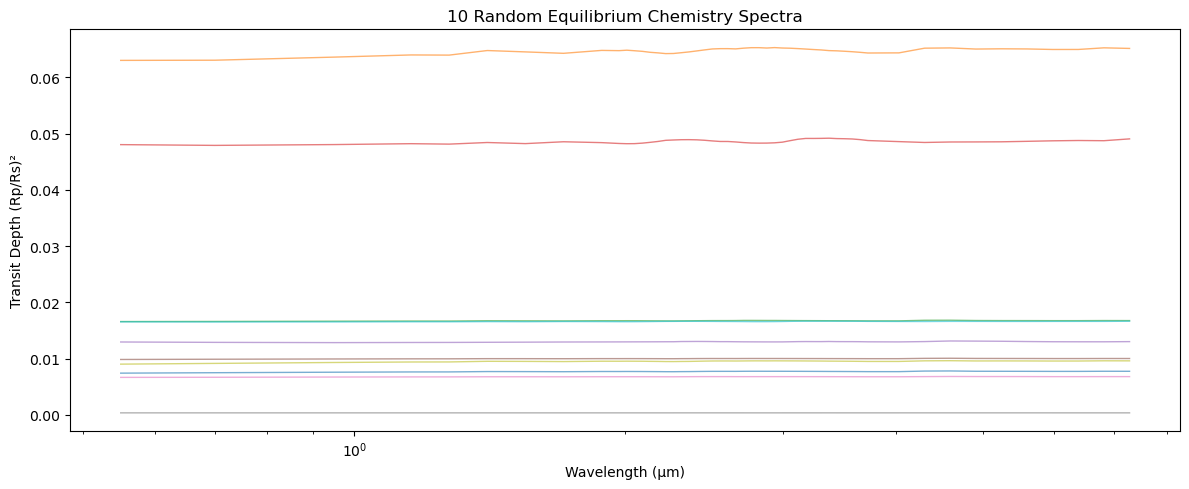

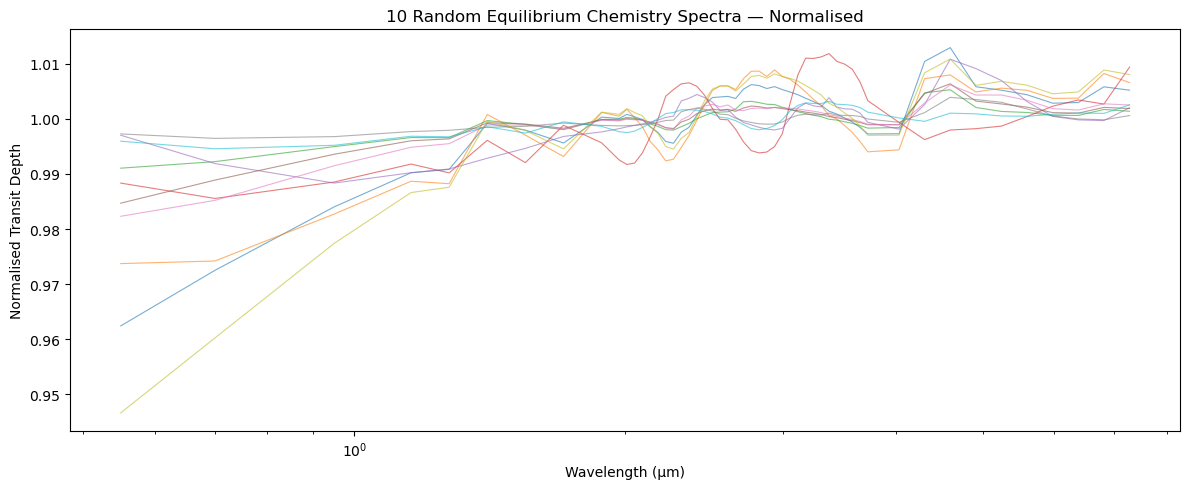

In [23]:
# ── Quick sanity check ────────────────────────
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))
idx = np.random.choice(len(spectra_eq), 10, replace=False)
for i in idx:
    ax.plot(wl_binned, spectra_eq[i],
            alpha=0.6, linewidth=1)
ax.set_xlabel('Wavelength (μm)')
ax.set_ylabel('Transit Depth (Rp/Rs)²')
ax.set_title('10 Random Equilibrium Chemistry Spectra')
ax.set_xscale('log')
plt.tight_layout()
plt.show()

# Normalised version
spectra_eq_norm = spectra_eq / spectra_eq.mean(
    axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(12, 5))
for i in idx:
    ax.plot(wl_binned, spectra_eq_norm[i],
            alpha=0.6, linewidth=0.8)
ax.set_xlabel('Wavelength (μm)')
ax.set_ylabel('Normalised Transit Depth')
ax.set_title('10 Random Equilibrium Chemistry Spectra — Normalised')
ax.set_xscale('log')
plt.tight_layout()
plt.show()

In [24]:
data_eq = np.hstack([spectra_eq, params_eq])
np.save('eq_chemistry_spectra.npy', spectra_eq)
np.save('eq_chemistry_params.npy', params_eq)
np.save('eq_chemistry_full.npy', data_eq)

print(f"Saved eq_chemistry_full.npy — shape: {data_eq.shape}")
print("Column order: spectrum (42 bins) + "
      "[Rstar, Rp, Mp, T, log_Met, C_to_O]")

Saved eq_chemistry_full.npy — shape: (113176, 58)
Column order: spectrum (42 bins) + [Rstar, Rp, Mp, T, log_Met, C_to_O]
